# Curvilinear grids: terrain-following coordinates

A `Grid` discretizes a box with uniformly spaced nodes. Many problems have a
boundary that is not a plane: the topography of a seismic survey, a sea floor,
a curved interface. A `CurvilinearGrid` keeps the logically Cartesian
*computational* grid, but places its nodes in *physical* space through a smooth
map, so the boundary is a grid line.

The point of the API is that nothing else changes. A `CurvilinearGrid` is used
exactly as a `Grid`:

* its Dimensions index the computational grid, so loops, halos, MPI and
  SubDomains are those of a `Grid`;
* derivatives such as `u.dx`, `u.laplace`, `div` and `grad`, nested
  derivatives and their transposes `.T` are derivatives w.r.t. the *physical*
  coordinates, evaluated through the chain rule with the metric terms of the
  map;
* the coordinates of sparse functions (sources, receivers) are physical.

This tutorial builds a terrain-following grid under a tilted free surface,
solves the acoustic wave equation on it, and compares the result with the
analytic image-source solution.

## A terrain-following map

`TerrainFollowing` stretches each column of the computational grid linearly
between a surface `s(x)` and a flat bottom at `z = depth`

$$
z(x, \eta) = s(x) + (\eta - o_z)\,\frac{\mathrm{depth} - s(x)}{l_z},
$$

with $o_z$ and $l_z$ the origin and extent of the vertical computational axis.
As for a `Grid`, the vertical axis is the last one and points down: the first
row of the grid is the surface, the last row the bottom. The surface is either
a callable of the lateral coordinates, as below, or an array with one value per
lateral node.

Here the surface is a plane dipping at 0.1 (about 5.7 degrees), from $z=0$ at
the left of a 3 km line to $z=300$ m at the right.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from devito import (CurvilinearGrid, Eq, Function, Grid, Operator, SparseTimeFunction,
                    TerrainFollowing, TimeFunction, solve)

slope, depth = 0.1, 1500.


def surface(x):
    return slope*x


grid = CurvilinearGrid(shape=(301, 151), extent=(3000., 1500.),
                       mapping=TerrainFollowing(surface=surface, depth=depth))
# As on a 2D Grid, the Dimensions are x and y, with y the vertical axis
x, y = grid.dimensions
print(f'Computational shape {grid.shape}, spacing {float(grid.spacing[0])} m')
print(f'Smallest physical cell size {grid.min_spacing:.2f} m')

Computational shape (301, 151), spacing 10.0 m
Smallest physical cell size 8.00 m


The grid builds, the first time they are needed, the physical coordinates of
its nodes, one `Function` per axis, the metric terms
$\partial \xi_j / \partial x_i$ and the Jacobian $J$, the ratio of a physical
to a computational cell area. For a vertical map only $\partial\eta/\partial x$
and $\partial\eta/\partial z$ vary in space; the other entries are constants
and stay symbolic.

In [2]:
grid.metrics

{(x, x): 1, (y, x): 0, (x, y): eta_x(x, y), (y, y): eta_y(x, y)}

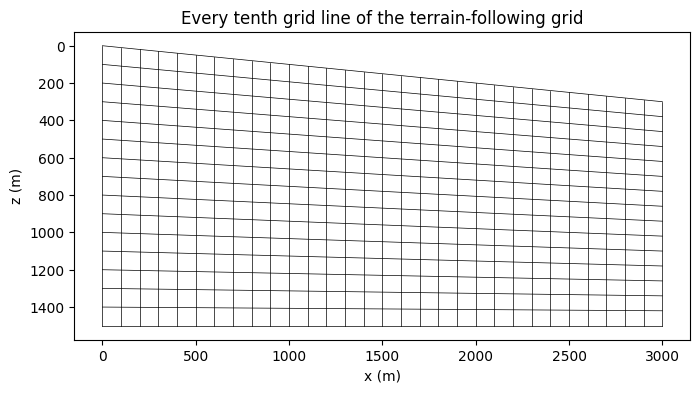

In [3]:
# NBVAL_IGNORE_OUTPUT
x_coord, z_coord = grid.coordinates

fig, ax = plt.subplots(figsize=(10, 4))
step = 10
# Lines of constant x, then lines of constant eta
ax.plot(x_coord.data[::step, :].T, z_coord.data[::step, :].T, 'k', lw=.5)
ax.plot(x_coord.data[:, ::step], z_coord.data[:, ::step], 'k', lw=.5)
ax.set_xlabel('x (m)')
ax.set_ylabel('z (m)')
ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_title('Every tenth grid line of the terrain-following grid')
plt.show()

## Physical derivatives

With $\xi$ and $\eta$ the computational coordinates, a physical first derivative
is the chain rule

$$
\frac{\partial u}{\partial x} = \frac{\partial \xi}{\partial x}
\frac{\partial u}{\partial \xi} + \frac{\partial \eta}{\partial x}
\frac{\partial u}{\partial \eta},
$$

which `Derivative` applies when it is evaluated: `u.dx` is still written
`u.dx`. Second derivatives add the products of metrics, the cross
computational derivative and the derivatives of the metrics, so that over a
flat surface they reduce to the usual stencils. The derivative w.r.t. the
computational coordinate itself is `u.dx(computational=True)`.

In [4]:
u = Function(name='u', grid=grid, space_order=2)
u.dx.evaluate

-u(x, y)/h_x + u(x + h_x, y)/h_x + (-0.5*u(x, y - h_y)/h_y + 0.5*u(x, y + h_y)/h_y)*eta_x(x, y)

A simple check: the physical derivatives of the physical depth $z$ are
$\partial z/\partial x = 0$ and $\partial z/\partial z = 1$, while its
computational derivative along $x$ is the slope of the grid lines.

In [5]:
# NBVAL_IGNORE_OUTPUT
depth_field = Function(name='depth_field', grid=grid, space_order=8)
dzdx = Function(name='dzdx', grid=grid, space_order=8)
dzdz = Function(name='dzdz', grid=grid, space_order=8)
dzdxi = Function(name='dzdxi', grid=grid, space_order=8)
depth_field.data_with_halo[:] = z_coord.data_with_halo

Operator([Eq(dzdx, depth_field.dx), Eq(dzdz, depth_field.dy),
          Eq(dzdxi, depth_field.dx(computational=True))]).apply()

NUMA domain count autodetection failed, assuming 1


Operator `Kernel` ran in 0.01 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=0.000136, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

In [6]:
interior = (slice(4, -4), slice(4, -4))
print(f'max |dz/dx|     = {np.abs(dzdx.data[interior]).max():.2e}')
print(f'max |dz/dz - 1| = {np.abs(dzdz.data[interior] - 1).max():.2e}')
print(f'dz/dxi at the surface = {dzdxi.data[150, 0]:.3f}')
assert np.abs(dzdx.data[interior]).max() < 1e-4
assert np.abs(dzdz.data[interior] - 1).max() < 1e-4

max |dz/dx|     = 1.02e-05
max |dz/dz - 1| = 1.25e-05
dz/dxi at the surface = 0.100


## A velocity model from a Cartesian grid

Models usually come on a Cartesian grid. `grid.resample(f, cartesian)` sets a
`Function` on the curvilinear grid to a Cartesian `Function` interpolated at
the physical nodes, along each column for a vertical map, and
`grid.resample(f, cartesian, transpose=True)` applies its exact transpose, e.g.
to bring a gradient back to the Cartesian grid. Nodes above the Cartesian model
take the value of its first row.

Here the model is a constant velocity of 1500 m/s, so that the result can be
checked against an analytic solution.

In [7]:
cartesian_grid = Grid(shape=(301, 151), extent=(3000., 1500.))
cartesian_velocity = Function(name='cartesian_velocity', grid=cartesian_grid)
cartesian_velocity.data[:] = 1500.

velocity = Function(name='velocity', grid=grid, space_order=8)
grid.resample(velocity, cartesian_velocity)

m = Function(name='m', grid=grid, space_order=8)
m.data[:] = 1/velocity.data**2

## Acoustic wave equation with a free surface

The wave equation is written as on a `Grid`. The time step is set from the
smallest physical cell size of the grid, `grid.min_spacing`.

The source and the receivers are placed by their physical coordinates: the
source 200 m below the surface at $x=1.5$ km, and 101 receivers 100 m below the
surface. Injection divides by the Jacobian at each node, so a source is a Dirac
in physical space.

The free surface $u=0$ is the first row of the grid. As on a `Grid`, it is
imposed with an odd mirror of the wavefield into the rows above it, along the
grid columns. Devito warns that these equations write to the halo, which is
what the mirror is meant to do.

In [8]:
# NBVAL_IGNORE_OUTPUT
space_order = 8
f0, t0, tn = 10., .12, 1.2
dt = .3*grid.min_spacing/1500.
nt = int(np.ceil(tn/dt)) + 1
time_values = np.arange(nt)*dt


def ricker(t):
    a = (np.pi*f0*(t - t0))**2
    return (1 - 2*a)*np.exp(-a)


source_position = np.array([1500., surface(1500.) + 200.])
src = SparseTimeFunction(name='src', grid=grid, npoint=1, nt=nt,
                         coordinates=source_position[None, :])
src.data[:, 0] = ricker(time_values)

receiver_x = np.linspace(1000., 2000., 101)
receiver_positions = np.stack([receiver_x, surface(receiver_x) + 100.], axis=1)
rec = SparseTimeFunction(name='rec', grid=grid, npoint=101, nt=nt,
                         coordinates=receiver_positions)

u = TimeFunction(name='u', grid=grid, space_order=space_order, time_order=2)
pde = m*u.dt2 - u.laplace
update = Eq(u.forward, solve(pde, u.forward))

# Odd mirror about the surface row
t = grid.stepping_dim
mirror = [Eq(u[t+1, x, 0], 0)]
mirror += [Eq(u[t+1, x, -k], -u[t+1, x, k]) for k in range(1, space_order//2 + 1)]

op = Operator([update] + mirror + src.inject(field=u.forward, expr=src*dt**2/m) +
              rec.interpolate(expr=u))

Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


In [9]:
# NBVAL_IGNORE_OUTPUT
snapshot_step = int(.55/dt)
op.apply(dt=dt, time_M=snapshot_step)
snapshot = u.data[(snapshot_step + 1) % 3].copy()
op.apply(dt=dt, time_m=snapshot_step + 1, time_M=nt - 2)

Operator `Kernel` ran in 0.03 s


Operator `Kernel` ran in 0.04 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=0.02495799999999999, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section1', rank=None),
                     PerfEntry(time=0.004629, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section2', rank=None),
                     PerfEntry(time=0.005364999999999981, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

The snapshot, drawn at the physical position of the nodes, shows the direct
wave and its reflection off the tilted surface, with the polarity flip of a
free surface.

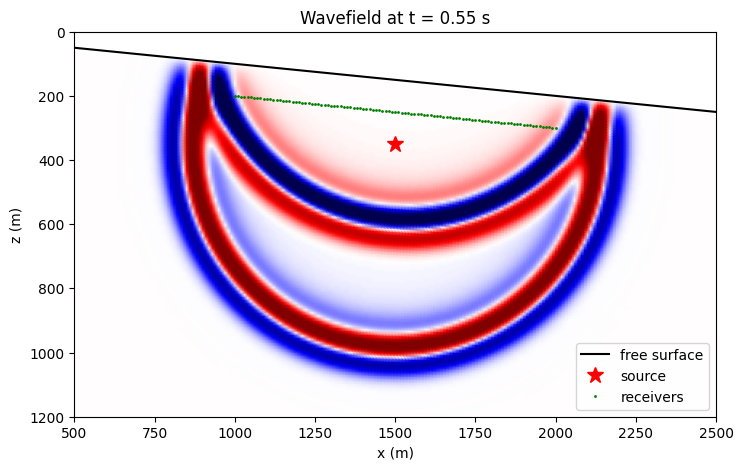

In [10]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 5))
clip = np.abs(snapshot).max()/2
ax.pcolormesh(x_coord.data, z_coord.data, snapshot, cmap='seismic',
              vmin=-clip, vmax=clip, shading='gouraud')
ax.plot(x_coord.data[:, 0], z_coord.data[:, 0], 'k', lw=1.5, label='free surface')
ax.plot(*source_position, 'r*', ms=12, label='source')
ax.plot(*receiver_positions.T, 'g.', ms=2, label='receivers')
ax.set_xlim(500., 2500.)
ax.set_ylim(1200., 0.)
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('z (m)')
ax.set_title(f'Wavefield at t = {(snapshot_step + 1)*dt:.2f} s')
ax.legend(loc='lower right')
plt.show()

## Comparison with the image-source solution

In a homogeneous medium bounded by a planar free surface, the wavefield is the
free-space field of the source minus that of its mirror image across the plane.
For $m\,u_{tt} - \Delta u = A\,s(t)\,\delta(\mathbf{x}-\mathbf{x}_s)$ in 2D, the
free-space field at distance $r$ is

$$
u(r, t) = \frac{A}{2\pi}\int_0^{\cosh^{-1}(t/\tau_0)}
s(t - \tau_0\cosh\theta)\,d\theta, \qquad \tau_0 = r/c,
$$

and the injection of `src` with weight `dt**2/m` is a source of amplitude
$A = h_\xi h_\eta$, the computational cell area, as on a `Grid`.

In [11]:
def free_space(r, t, amplitude, c=1500.):
    tau0 = r/c
    field = np.zeros_like(t)
    for i, ti in enumerate(t):
        if ti <= tau0:
            continue
        theta = np.linspace(0, np.arccosh(ti/tau0), 2001)
        field[i] = np.trapezoid(ricker(ti - tau0*np.cosh(theta)), theta)
    return amplitude*field/(2*np.pi)


# Mirror image of the source across the plane z = slope*x
normal = np.array([slope, -1.])
image_position = source_position - 2*(normal @ source_position)/(normal @ normal)*normal

amplitude = np.prod(np.array(grid.spacing, dtype=np.float64))
analytic = np.zeros((nt, len(receiver_positions)))
for j, position in enumerate(receiver_positions):
    direct = np.linalg.norm(position - source_position)
    image = np.linalg.norm(position - image_position)
    analytic[:, j] = (free_space(direct, time_values, amplitude) -
                      free_space(image, time_values, amplitude))

error = np.linalg.norm(rec.data - analytic)/np.linalg.norm(analytic)
print(f'Relative L2 misfit to the image-source solution: {error:.3f}')
assert error < .05

Relative L2 misfit to the image-source solution: 0.017


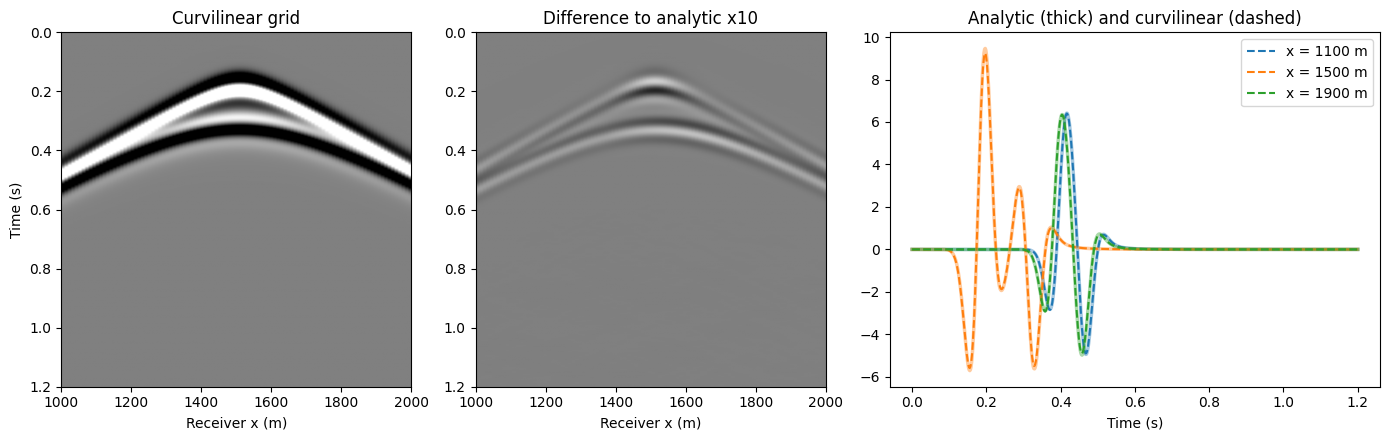

In [12]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5),
                         gridspec_kw={'width_ratios': [1, 1, 1.4]})
extent = [receiver_x[0], receiver_x[-1], time_values[-1], 0]
clip = np.abs(analytic).max()/3
for ax, data, title in zip(axes[:2], [rec.data, 10*(rec.data - analytic)],
                           ['Curvilinear grid', 'Difference to analytic x10'],
                           strict=True):
    ax.imshow(data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip, extent=extent)
    ax.set_xlabel('Receiver x (m)')
    ax.set_title(title)
axes[0].set_ylabel('Time (s)')
for j, color in zip([10, 50, 90], ['C0', 'C1', 'C2'], strict=True):
    axes[2].plot(time_values, analytic[:, j], color=color, lw=2.5, alpha=.4)
    axes[2].plot(time_values, rec.data[:, j], '--', color=color,
                 label=f'x = {receiver_x[j]:.0f} m')
axes[2].set_xlabel('Time (s)')
axes[2].set_title('Analytic (thick) and curvilinear (dashed)')
axes[2].legend()
plt.tight_layout()
plt.show()

The traces match the analytic solution, both the direct wave and the surface
reflection, within a few percent: the remaining misfit comes from the
finite-difference dispersion and from the odd mirror being taken along the
vertical grid columns, which are not normal to a tilted surface.